In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

In [3]:
# Create default configuration storage object.
store = qnrl.store.HashStore()

In [4]:
from qnrl.algorithms.c51 import C51
from qnrl.optimizer import *
from qnrl.gym import *
from qnrl.modules import *

# num_atoms = 101
num_atoms = 2**5

# Experiment configuration.
config = C51(
    buffer_size=10_000,
    seed=0,
    batch_size=128,
    # total_timesteps=500_000,
    total_timesteps=20_000,
    learning_starts=10_000,
    policy_update_frequency=10,
    target_update_frequency=500,
    gamma=0.99,
    tau=1.0,
    eps_start=1,
    eps_end=5e-2,
    eps_exploration=0.5,
    #
    env=EnvConfig(env_id="CartPole-v1"),
    num_atoms=num_atoms,
    z_min=-100,
    z_max=100,
    model=Sequential(
        layers={
            'RescaleInput': RescaleInput(scale=[2.4, 2.5, 0.21, 2.5]),
            'QNetworkLinear': DistQNetworkLinear(
                din=4,
                num_actions=2,
                num_atoms=num_atoms,
                douts=[120, 84],
                rngs_kwargs=dict(default=42),
            ),
        },
    ),
    # optimizer=Adam(learning_rate=2.5e-4),
    # optimizer=Adam(learning_rate=2.5e-3),
    optimizer=Adam(learning_rate=1e-3),
)

if store.exists(config):
    print(f"Already exists in store")
    cfg_hash, cfg_str = store.hash(config)
else:
    print(f"New hash")
    # Generate hash for the current config and store it for later retrieval.
    cfg_hash, cfg_str = store.store_obj(config)

print(f"Config String: {cfg_str}")
print(f"Config Hash: {cfg_hash}")

New hash
Config String: {"type": "c51", "env": {"env_id": "CartPole-v1", "render_mode": null, "max_episode_steps": null, "extra_args": null}, "metric_manager": null, "checkpoint": null, "model": {"type": "Sequential", "layers": {"RescaleInput": {"type": "RescaleInput", "scale": [2.4, 2.5, 0.21, 2.5]}, "QNetworkLinear": {"type": "DistQNetworkLinear", "din": 4, "num_actions": 2, "num_atoms": 32, "douts": [120, 84], "rngs_kwargs": {"default": 42}}}, "key_order": ["RescaleInput", "QNetworkLinear"]}, "optimizer": {"type": "adam", "learning_rate": 0.001, "b1": 0.9, "b2": 0.999, "eps": 1e-08, "eps_root": 0.0, "mu_dtype": null, "nesterov": false}, "num_atoms": 32, "z_min": -100, "z_max": 100, "buffer_size": 10000, "seed": 0, "batch_size": 128, "total_timesteps": 20000, "learning_starts": 10000, "policy_update_frequency": 10, "target_update_frequency": 500, "gamma": 0.99, "tau": 1.0, "eps_start": 1, "eps_end": 0.05, "eps_exploration": 0.5}
Config Hash: 940582a3-6b34-5392-93a0-d58e393fc42c


In [5]:
qnrl.tools.get_model_total_parameter_count(config.model)

16204

In [6]:
train = True
save_metrics = True
metric_filepath = Path(f"./metrics/{cfg_hash}.json")

In [7]:
if metric_filepath.exists() and not train:
    print(f"Loading existing train results")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    history_list = qnrl.tools.load_train_results(metric_filepath)
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
else:
    print(f"Training")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    
    history_list = config.train()
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
    
    # Preserve training results.
    if save_metrics:
        qnrl.tools.save_train_results(metric_filepath, history_list)

Training
Store: hashstore.json
Hash: 940582a3-6b34-5392-93a0-d58e393fc42c
History: metrics/940582a3-6b34-5392-93a0-d58e393fc42c.json


100%|██████████| 20000/20000 [00:27<00:00, 716.93step/s, episode_step=19729, episode_reward=326, episode_length=326, episode_time=0.514, loss_step=2e+4, loss=0.2841096010976938]  


Text(0, 0.5, 'episode_reward')

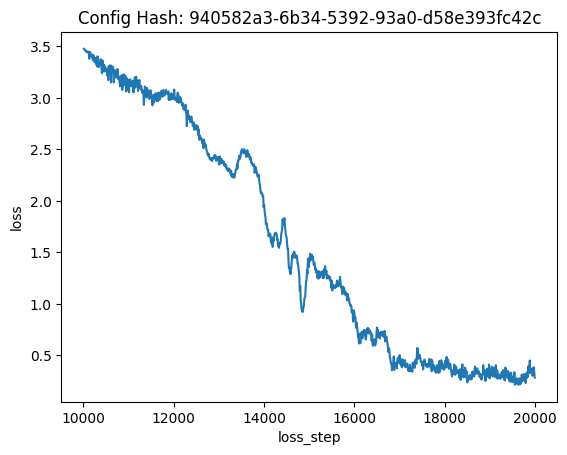

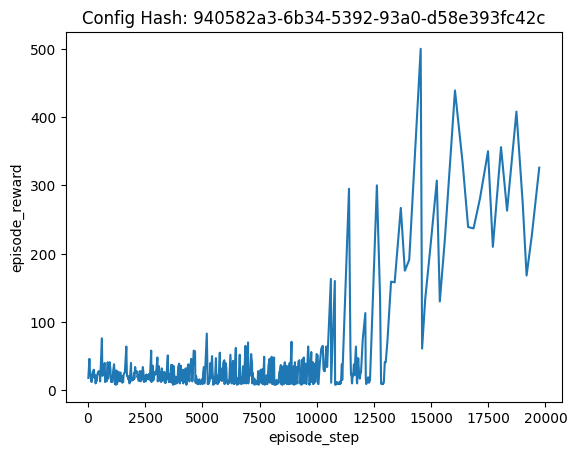

In [8]:
import matplotlib.pyplot as plt

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['loss_step'], history_dict['loss'])
plt.xlabel('loss_step')
plt.ylabel('loss')

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['episode_step'], history_dict['episode_reward'])
plt.xlabel('episode_step')
plt.ylabel('episode_reward')

./figures/940582a3-6b34-5392-93a0-d58e393fc42c.pdf


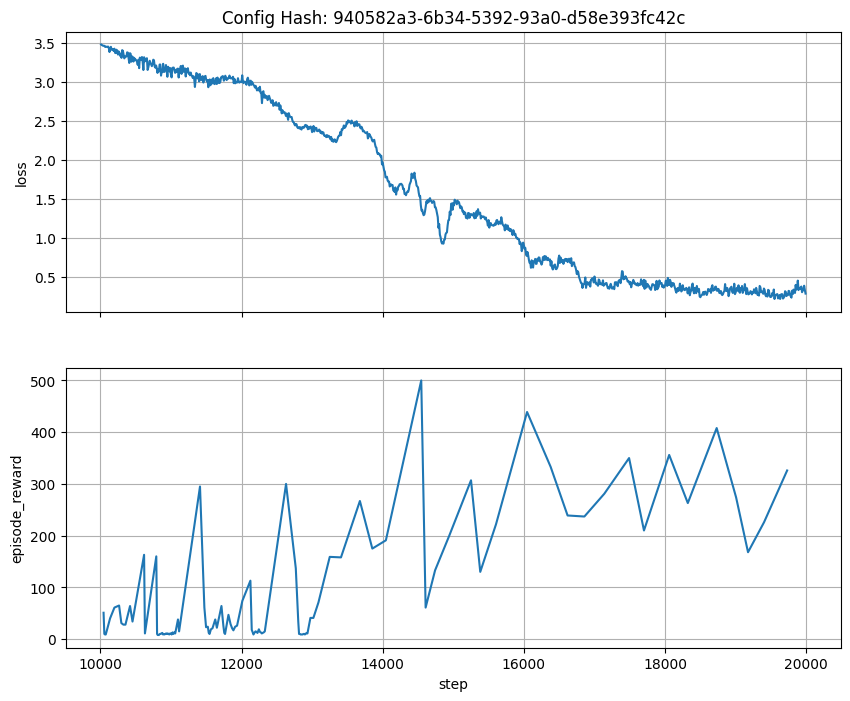

In [9]:
# Plot loss and episode reward on the same plot.

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

fig, axs = plt.subplots(2,1, sharex=True, figsize=(10,8))
axs = axs.squeeze()

axs[0].set_title(f"Config Hash: {cfg_hash}")
plt.xlabel('step')

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['loss_step']) >= config.learning_starts
history_dict['loss_step'] = np.array(history_dict['loss_step'])[idx]
history_dict['loss'] = np.array(history_dict['loss'])[idx]

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['episode_step']) >= config.learning_starts
history_dict['episode_step'] = np.array(history_dict['episode_step'])[idx]
history_dict['episode_reward'] = np.array(history_dict['episode_reward'])[idx]

axs[0].plot(history_dict['loss_step'], history_dict['loss'])
axs[0].set_ylabel('loss')
axs[0].grid() # Turn on a grid.

axs[1].plot(history_dict['episode_step'], history_dict['episode_reward'])
axs[1].set_ylabel('episode_reward')
axs[1].grid() # Turn on a grid.

# Save the figure file.
figfile = f"./figures/{cfg_hash}.pdf"
fig.savefig(figfile)
print(figfile)

In [10]:
eval_metric_list = config.eval()
eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

for key in ('episode_step','episode_reward','episode_length','episode_time',):
    print(f"{key}: {eval_metric_dict[key][0]}")

  1%|          | 217/20000 [00:00<00:03, 5352.61step/s, episode_step=217, episode_reward=218, episode_length=218, episode_time=0.0406]

episode_step: 217
episode_reward: 218.0
episode_length: 218
episode_time: 0.040585
